# 3D Steady-State Heat Conduction in Heterogeneous Media

We define a 3D domain of 30 mm × 30 mm footprint. The vertical stack consists of 7 functional layers. The top layer (active dies) is heterogeneously partitioned in the X-direction into four components: Memory 1, IC 1, IC 2, and Memory 2.

The steady-state 3D heat conduction equation with spatially variable thermal conductivity $k(x,y,z)$ and volumetric heat generation $q'''(x,y,z)$ is given by:

$$\nabla \cdot (k(x,y,z) \nabla T(x,y,z)) + q'''(x,y,z) = 0$$

Expanding in Cartesian coordinates:

$$\frac{\partial}{\partial x}\left(k \frac{\partial T}{\partial x}\right) + \frac{\partial}{\partial y}\left(k \frac{\partial T}{\partial y}\right) + \frac{\partial}{\partial z}\left(k \frac{\partial T}{\partial z}\right) + q''' = 0$$

To handle steep material property discontinuities across thin physical layers (e.g., Silicon to Microbumps), we integrate this PDE over a 3D rectangular control volume $V_P = \Delta x \Delta y \Delta z$ centered at node $P(i,j,k)$:

$$\iiint_{V_P} \nabla \cdot (k \nabla T) \, dV + \iiint_{V_P} q''' \, dV = 0$$

Applying Gauss's Divergence Theorem converts the volume integral of the flux divergence into a surface integral over the control volume faces $\partial V_P$:

$$\iint_{\partial V_P} (k \nabla T) \cdot \mathbf{n} \, dA + q'''_P \Delta x \Delta y \Delta z = 0$$

| Direction | Coordinate Axis | Face Symbol | Interface Location | Neighbor Node Symbol | Neighbor Grid Index |
| --- | --- | --- | --- | --- | --- |
| **East** | $+X$ | $e$ | $x_P + \Delta x / 2$ | $E$ | $(i+1, j, k)$ |
| **West** | $-X$ | $w$ | $x_P - \Delta x / 2$ | $W$ | $(i-1, j, k)$ |
| **North** | $+Y$ | $n$ | $y_P + \Delta y / 2$ | $N$ | $(i, j+1, k)$ |
| **South** | $-Y$ | $s$ | $y_P - \Delta y / 2$ | $S$ | $(i, j-1, k)$ |
| **Top** | $+Z$ | $t$ | $z_P + \Delta z / 2$ | $T$ | $(i, j, k+1)$ |
| **Bottom** | $-Z$ | $b$ | $z_P - \Delta z / 2$ | $B$ | $(i, j, k-1)$ |

For a 3D Cartesian cell with six bounding faces—East ($e$), West ($w$), North ($n$), South ($s$), Top ($t$), and Bottom ($b$)—the surface integral decomposes into:

$$\left[ \left( k \frac{\partial T}{\partial x} \right)_e - \left( k \frac{\partial T}{\partial x} \right)_w \right] \Delta y \Delta z + \left[ \left( k \frac{\partial T}{\partial y} \right)_n - \left( k \frac{\partial T}{\partial y} \right)_s \right] \Delta x \Delta z + \left[ \left( k \frac{\partial T}{\partial z} \right)_t - \left( k \frac{\partial T}{\partial z} \right)_b \right] \Delta x \Delta y + q'''_P \Delta x \Delta y \Delta z = 0$$

At the interface between two dissimilar materials (e.g., cell $P$ with $k_P$ and neighbor $E$ with $k_E$), using an arithmetic mean introduces significant numerical error. We derive the exact interface thermal conductivity $k_e$ by enforcing heat flux continuity across the interface boundary $x_e$.

Let $T_P$ be the temperature at cell center $x_P$, $T_E$ at $x_E$, and $T_e$ at the interface $x_e$. The distance from $x_P$ to $x_e$ is $\delta x_P = \frac{\Delta x}{2}$, and from $x_e$ to $x_E$ is $\delta x_E = \frac{\Delta x}{2}$. The heat flux from $P$ to interface $e$ is:

$$q_e'' = k_P \frac{T_P - T_e}{\Delta x / 2}$$

The heat flux from interface $e$ to $E$ is:

$$q_e'' = k_E \frac{T_e - T_E}{\Delta x / 2}$$

Equating fluxes for energy conservation across the interface:

$$k_P (T_P - T_e) = k_E (T_e - T_E)$$

Solving for the interface temperature $T_e$:

$$k_P T_P + k_E T_E = (k_P + k_E) T_e \implies T_e = \frac{k_P T_P + k_E T_E}{k_P + k_E}$$

Substituting $T_e$ back into the heat flux equation yields:

$$q_e'' = \frac{2 k_P}{\Delta x} \left( T_P - \frac{k_P T_P + k_E T_E}{k_P + k_E} \right) = \frac{2 k_P}{\Delta x} \left( \frac{k_E T_P - k_E T_E}{k_P + k_E} \right) = \left( \frac{2 k_P k_E}{k_P + k_E} \right) \frac{T_P - T_E}{\Delta x}$$

Comparing this result to Fourier's law $q_e'' = k_e \frac{T_P - T_E}{\Delta x}$ yields the harmonic mean formulation:

$$k_e = \frac{2 k_P k_E}{k_P + k_E}$$

All remaining interface conductivities ($k_w, k_n, k_s, k_t, k_b$) follow the identical harmonic mean calculation using their respective adjacent cell values.

Using these interface conductivities, we define the 6 face thermal conductances $C$ (W/K):

$$C_E = \frac{k_e \Delta y \Delta z}{\Delta x}, \quad C_W = \frac{k_w \Delta y \Delta z}{\Delta x}$$

$$C_N = \frac{k_n \Delta x \Delta z}{\Delta y}, \quad C_S = \frac{k_s \Delta x \Delta z}{\Delta y}$$

$$C_T = \frac{k_t \Delta x \Delta y}{\Delta z}, \quad C_B = \frac{k_b \Delta x \Delta y}{\Delta z}$$

Substituting these conductances into the discrete flux balance:

$$-C_E(T_P - T_E) - C_W(T_P - T_W) - C_N(T_P - T_N) - C_S(T_P - T_S) - C_T(T_P - T_T) - C_B(T_P - T_B) + q'''_P \Delta x \Delta y \Delta z = 0$$

Distributing conductances across temperature differences:

$$-C_E T_P + C_E T_E - C_W T_P + C_W T_W - C_N T_P + C_N T_N - C_S T_P + C_S T_S - C_T T_P + C_T T_T - C_B T_P + C_B T_B + q'''_P \Delta x \Delta y \Delta z = 0$$

Grouping terms containing $T_P$ and separating neighbor temperatures:

$$-(C_E + C_W + C_N + C_S + C_T + C_B) T_P + C_E T_E + C_W T_W + C_N T_N + C_S T_S + C_T T_T + C_B T_B + q'''_P \Delta x \Delta y \Delta z = 0$$

Isolating $T_P$ terms on the left-hand side:

$$(C_E + C_W + C_N + C_S + C_T + C_B) T_P = C_E T_E + C_W T_W + C_N T_N + C_S T_S + C_T T_T + C_B T_B + q'''_P \Delta x \Delta y \Delta z$$

To express this in canonical algebraic form, we define:

* Neighbor Coefficients ($a_{nb}$): For any neighbor face $nb \in \{E, W, N, S, T, B\}$, the coefficient equals the face conductance:

$$a_E = C_E, \quad a_W = C_W, \quad a_N = C_N, \quad a_S = C_S, \quad a_T = C_T, \quad a_B = C_B$$


* Volumetric Source Term ($S_u$): The heat generation integrated over cell volume $\Delta V = \Delta x \Delta y \Delta z$:

$$S_u = q'''_P \Delta x \Delta y \Delta z$$


* Central Node Coefficient ($a_P$): The sum of all surrounding neighbor coefficients:

$$a_P = \sum_{nb} a_{nb} = a_E + a_W + a_N + a_S + a_T + a_B$$


Substituting $a_{nb}$, $a_P$, and $S_u$ yields the canonical local algebraic equation for cell $P$:

$$a_P T_P = \sum_{nb} a_{nb} T_{nb} + S_u = a_E T_E + a_W T_W + a_N T_N + a_S T_S + a_T T_T + a_B T_B + S_u$$

To assemble the global system of equations $\mathbf{A} \mathbf{T} = \mathbf{b}$, each 3D node index $(i, j, k)$ is mapped to a 1D global index $m \in [0, N_{total} - 1]$ using column-major ordering:

$$m = i + j \cdot N_x + k \cdot (N_x \cdot N_y)$$

where $i \in [0, N_x - 1]$, $j \in [0, N_y - 1]$, $k \in [0, N_z - 1]$, and total node count $N_{total} = N_x N_y N_z$.

Solving massive sparse matrix system...
Solve complete. Max Package Temp (Hotspot): 40.25 °C


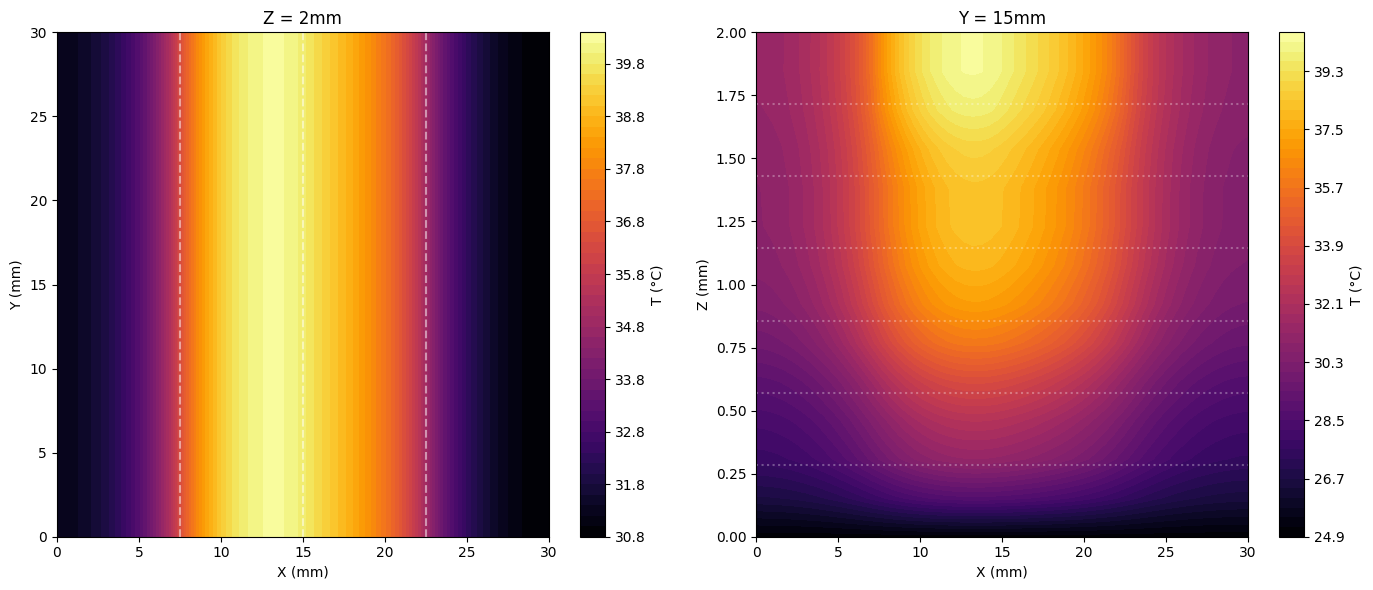

In [8]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
'''
The script below builds the 3D structured mesh, maps the heterogeneous properties 
$k$ and $q```$ to the specific Cartesian domains, constructs the massive sparse 
coefficient matrix using the 7-point stencil, and solves the system efficiently 
using SciPy's sparse linear algebra backend.

'''

# ==========================================
# 1. Domain & Grid Setup
# ==========================================
Lx, Ly = 0.03, 0.03  # 30mm x 30mm footprint
Nx, Ny, Nz = 60, 60, 14  # 3D Grid resolution (Nz = 2 cells per layer for 7 layers)

dx = Lx / Nx
dy = Ly / Ny
# To simplify matrix setup, we'll use a uniform dz mesh and map layers to it.
# Total thickness = 1000+100+500+50+200+50+100 = 2000 um = 2mm
Lz = 0.002
dz = Lz / Nz
dV = dx * dy * dz

# Matrices for thermal conductivity (k) and heat generation (Q)
k_map = np.zeros((Nx, Ny, Nz))
Q_map = np.zeros((Nx, Ny, Nz))

# ==========================================
# 2. Material & Property Mapping
# ==========================================
# Define layers in Z-axis (2 index increments per layer)
# PCB (z: 0-1), Bumps (2-3), Package (4-5), TSV (6-7), Interposer (8-9), TSV (10-11), Dies (12-13)
layers = [
    (0, 2, 1.0, 0.0),       # PCB
    (2, 4, 3.0, 0.0),       # Bumps/Underfill
    (4, 6, 2.0, 0.0),       # Package
    (6, 8, 5.0, 0.0),       # Microbumps
    (8, 10, 130.0, 0.0),    # Silicon Interposer
    (10, 12, 5.0, 0.0)      # Microbumps
]

for z_start, z_end, k_val, q_val in layers:
    k_map[:, :, z_start:z_end] = k_val
    Q_map[:, :, z_start:z_end] = q_val

# Top Layer (z: 12-14) - Active Dies Heterogeneous mapping
k_map[:, :, 12:14] = 130.0  # Silicon
Q_map[:, :, 12:14] = 0.0

# Partition X-axis for Mem1, IC1, IC2, Mem2
# Indices: 0-15 (Mem1), 15-30 (IC1), 30-45 (IC2), 45-60 (Mem2)
Q_map[0:15, :, 12:14] = 50e6    # Mem1: 50 W/cm^3
Q_map[15:30, :, 12:14] = 250e6  # IC1: 250 W/cm^3 (Primary Hotspot)
Q_map[30:45, :, 12:14] = 200e6  # IC2: 200 W/cm^3 
Q_map[45:60, :, 12:14] = 50e6   # Mem2: 50 W/cm^3

# ==========================================
# 3. Sparse Matrix Assembly (FVM)
# ==========================================
N_total = Nx * Ny * Nz
A = sp.dok_matrix((N_total, N_total), dtype=np.float64)
b = np.zeros(N_total)

Tamb = 25.0  # Ambient / Bottom sink temperature
h_top = 2000.0  # Heat transfer coefficient at top (e.g., active heat sink) W/m^2K

def get_idx(i, j, k):
    return i + j*Nx + k*Nx*Ny

# Harmonic mean for interface conductivity
def harm_mean(k1, k2):
    return 2.0 * k1 * k2 / (k1 + k2 + 1e-15)

for k in range(Nz):
    for j in range(Ny):
        for i in range(Nx):
            idx = get_idx(i, j, k)
            
            # Bottom Dirichlet Boundary (Fixed to Tamb)
            if k == 0:
                A[idx, idx] = 1.0
                b[idx] = Tamb
                continue
                
            a_P = 0.0
            k_P = k_map[i, j, k]
            
            # X-direction (East / West)
            if i > 0:
                k_int = harm_mean(k_P, k_map[i-1, j, k])
                C_W = (k_int * dy * dz) / dx
                A[idx, get_idx(i-1, j, k)] = -C_W
                a_P += C_W
            if i < Nx - 1:
                k_int = harm_mean(k_P, k_map[i+1, j, k])
                C_E = (k_int * dy * dz) / dx
                A[idx, get_idx(i+1, j, k)] = -C_E
                a_P += C_E
                
            # Y-direction (North / South)
            if j > 0:
                k_int = harm_mean(k_P, k_map[i, j-1, k])
                C_S = (k_int * dx * dz) / dy
                A[idx, get_idx(i, j-1, k)] = -C_S
                a_P += C_S
            if j < Ny - 1:
                k_int = harm_mean(k_P, k_map[i, j+1, k])
                C_N = (k_int * dx * dz) / dy
                A[idx, get_idx(i, j+1, k)] = -C_N
                a_P += C_N
                
            # Z-direction (Top / Bottom)
            k_int = harm_mean(k_P, k_map[i, j, k-1])
            C_B = (k_int * dx * dy) / dz
            A[idx, get_idx(i, j, k-1)] = -C_B
            a_P += C_B
            
            if k < Nz - 1:
                k_int = harm_mean(k_P, k_map[i, j, k+1])
                C_T = (k_int * dx * dy) / dz
                A[idx, get_idx(i, j, k+1)] = -C_T
                a_P += C_T
            else:
                # Top boundary: Convection
                C_conv = h_top * dx * dy
                a_P += C_conv
                b[idx] += C_conv * Tamb
                
            # Central coefficient & Source term
            A[idx, idx] = a_P
            b[idx] += Q_map[i, j, k] * dV

# ==========================================
# 4. Direct Solution
# ==========================================
print("Solving massive sparse matrix system...")
A_csr = A.tocsr()
T_flat = spla.spsolve(A_csr, b)
T_3D = T_flat.reshape((Nx, Ny, Nz), order='F') # F-order ensures correct i,j,k reconstruction
print(f"Solve complete. Max Package Temp (Hotspot): {np.max(T_3D):.2f} °C")

# ==========================================
# 5. Visualization
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

X, Y = np.meshgrid(np.linspace(0, Lx*1000, Nx), np.linspace(0, Ly*1000, Ny))
T_top = T_3D[:, :, -1].T  # Transpose for correct X-Y orientation
c1 = axes[0].contourf(X, Y, T_top, levels=50, cmap='inferno')
fig.colorbar(c1, ax=axes[0], label='T (°C)')
axes[0].set_title('Z = 2mm')
axes[0].set_xlabel('X (mm)')
axes[0].set_ylabel('Y (mm)')
axes[0].axvline(x=7.5, color='white', linestyle='--', alpha=0.5)
axes[0].axvline(x=15.0, color='white', linestyle='--', alpha=0.5)
axes[0].axvline(x=22.5, color='white', linestyle='--', alpha=0.5)

# Plot 2: Cross-Sectional Slice (X-Z plane at center Y)
X_xz, Z_xz = np.meshgrid(np.linspace(0, Lx*1000, Nx), np.linspace(0, Lz*1000, Nz))
T_slice = T_3D[:, Ny//2, :].T
c2 = axes[1].contourf(X_xz, Z_xz, T_slice, levels=50, cmap='inferno')
fig.colorbar(c2, ax=axes[1], label='T (°C)')
axes[1].set_title('Y = 15mm')
axes[1].set_xlabel('X (mm)')
axes[1].set_ylabel('Z (mm)')
# Add layer delineations
for z_idx in [2, 4, 6, 8, 10, 12]:
    axes[1].axhline(y=z_idx*dz*1000, color='white', linestyle=':', alpha=0.3)

plt.tight_layout()
plt.savefig('../lectures/figures/x_y_T_heat_conduction_numerical_2D_heterogeneous_steady.pdf',dpi=300)
plt.show()